# Partie 1 — Analyse descriptive du dataset
Objectif : comprendre les données avant de construire un modèle de prédiction du risque d'incendie.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
couleurs = {0: 'tab:blue', 1: 'tab:red'}   # 0 = pas de feu, 1 = feu

## 1. Description du dataset

In [2]:
df = pd.read_csv('DatasetMorocco.csv')

print('Nombre de lignes   :', df.shape[0])
print('Nombre de colonnes :', df.shape[1])
df.head()

Nombre de lignes   : 299
Nombre de colonnes : 15


,Fire,acq_date,acq_time,humidity_percent,precipitation_mm,pressure_hPa,temperature_C,wind_direction_deg,wind_speed_mps,longitude,latitude,NDVI,NDMI,NDWI,NBR
0,0,2022-01-01,221,50.305471,0.0,943.095352,12.053644,298.354195,1.211075,-3.435720,34.505224,0.118925,-0.202849,-0.271944,-0.130924
1,1,2022-01-01,221,71.519658,0.0,968.825352,7.565363,169.009182,2.057297,-5.118192,33.945032,-0.333333,0.176471,0.795918,0.333333
2,1,2022-01-01,1340,61.788530,0.0,1019.161758,19.497369,312.008412,0.708083,-6.166009,34.877394,0.054914,-0.242592,-0.119941,-0.263492
3,0,2022-01-02,201,39.120900,0.0,901.557969,8.234415,97.171733,0.543159,-4.291256,34.755224,0.291355,-0.254314,-0.456077,-0.177430
4,0,2022-01-02,1321,43.353296,0.0,973.095703,20.696130,343.057416,1.462190,-6.062857,33.629880,0.258453,0.047219,-0.275808,0.149858


In [3]:
# Type de chaque colonne
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Fire                299 non-null    int64  
 1   acq_date            299 non-null    str    
 2   acq_time            299 non-null    int64  
 3   humidity_percent    299 non-null    float64
 4   precipitation_mm    299 non-null    float64
 5   pressure_hPa        299 non-null    float64
 6   temperature_C       299 non-null    float64
 7   wind_direction_deg  299 non-null    float64
 8   wind_speed_mps      299 non-null    float64
 9   longitude           299 non-null    float64
 10  latitude            299 non-null    float64
 11  NDVI                299 non-null    float64
 12  NDMI                299 non-null    float64
 13  NDWI                299 non-null    float64
 14  NBR                 299 non-null    float64
dtypes: float64(12), int64(2), str(1)
memory usage: 35.2 KB


In [4]:
# Valeurs manquantes et doublons
print('Valeurs manquantes :', df.isnull().sum().sum())
print('Lignes dupliquées  :', df.duplicated().sum())
print('Période            :', df['acq_date'].min(), '->', df['acq_date'].max())

Valeurs manquantes : 0
Lignes dupliquées  : 0
Période            : 2022-01-01 -> 2022-05-07


In [5]:
# Statistiques descriptives (moyenne, écart-type, min, max, quartiles)
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Fire,299.0,0.61,0.49,0.00,0.00,1.00,1.00,1.00
acq_time,299.0,848.40,561.68,110.00,213.00,1250.00,1333.00,1430.00
humidity_percent,299.0,59.71,25.17,14.37,39.01,59.11,84.46,100.00
precipitation_mm,299.0,0.03,0.19,0.00,0.00,0.00,0.00,2.49
pressure_hPa,299.0,961.76,45.86,841.56,928.31,969.89,998.14,1024.29
temperature_C,299.0,14.09,5.49,0.76,9.46,14.93,18.44,28.87
wind_direction_deg,299.0,169.48,104.00,3.48,75.89,168.79,265.01,354.96
wind_speed_mps,299.0,2.02,1.27,0.22,1.34,1.72,2.37,9.76
longitude,299.0,-4.97,1.09,-6.68,-5.76,-5.21,-4.27,-2.52
latitude,299.0,34.60,0.60,33.54,34.00,34.72,35.00,35.87


## 2. Distribution des classes (variable cible `Fire`)

Fire
1    181
0    118
Name: count, dtype: int64
Fire
1    0.61
0    0.39
Name: proportion, dtype: float64


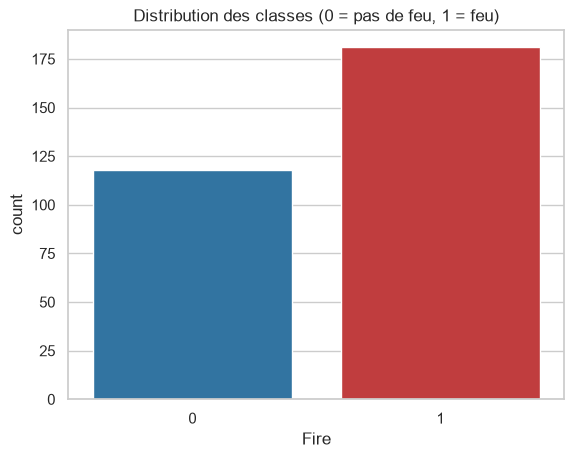

In [6]:
print(df['Fire'].value_counts())
print(df['Fire'].value_counts(normalize=True).round(2))

sns.countplot(data=df, x='Fire', hue='Fire', palette=couleurs, legend=False)
plt.title('Distribution des classes (0 = pas de feu, 1 = feu)')
plt.show()

## 3. Distribution des features

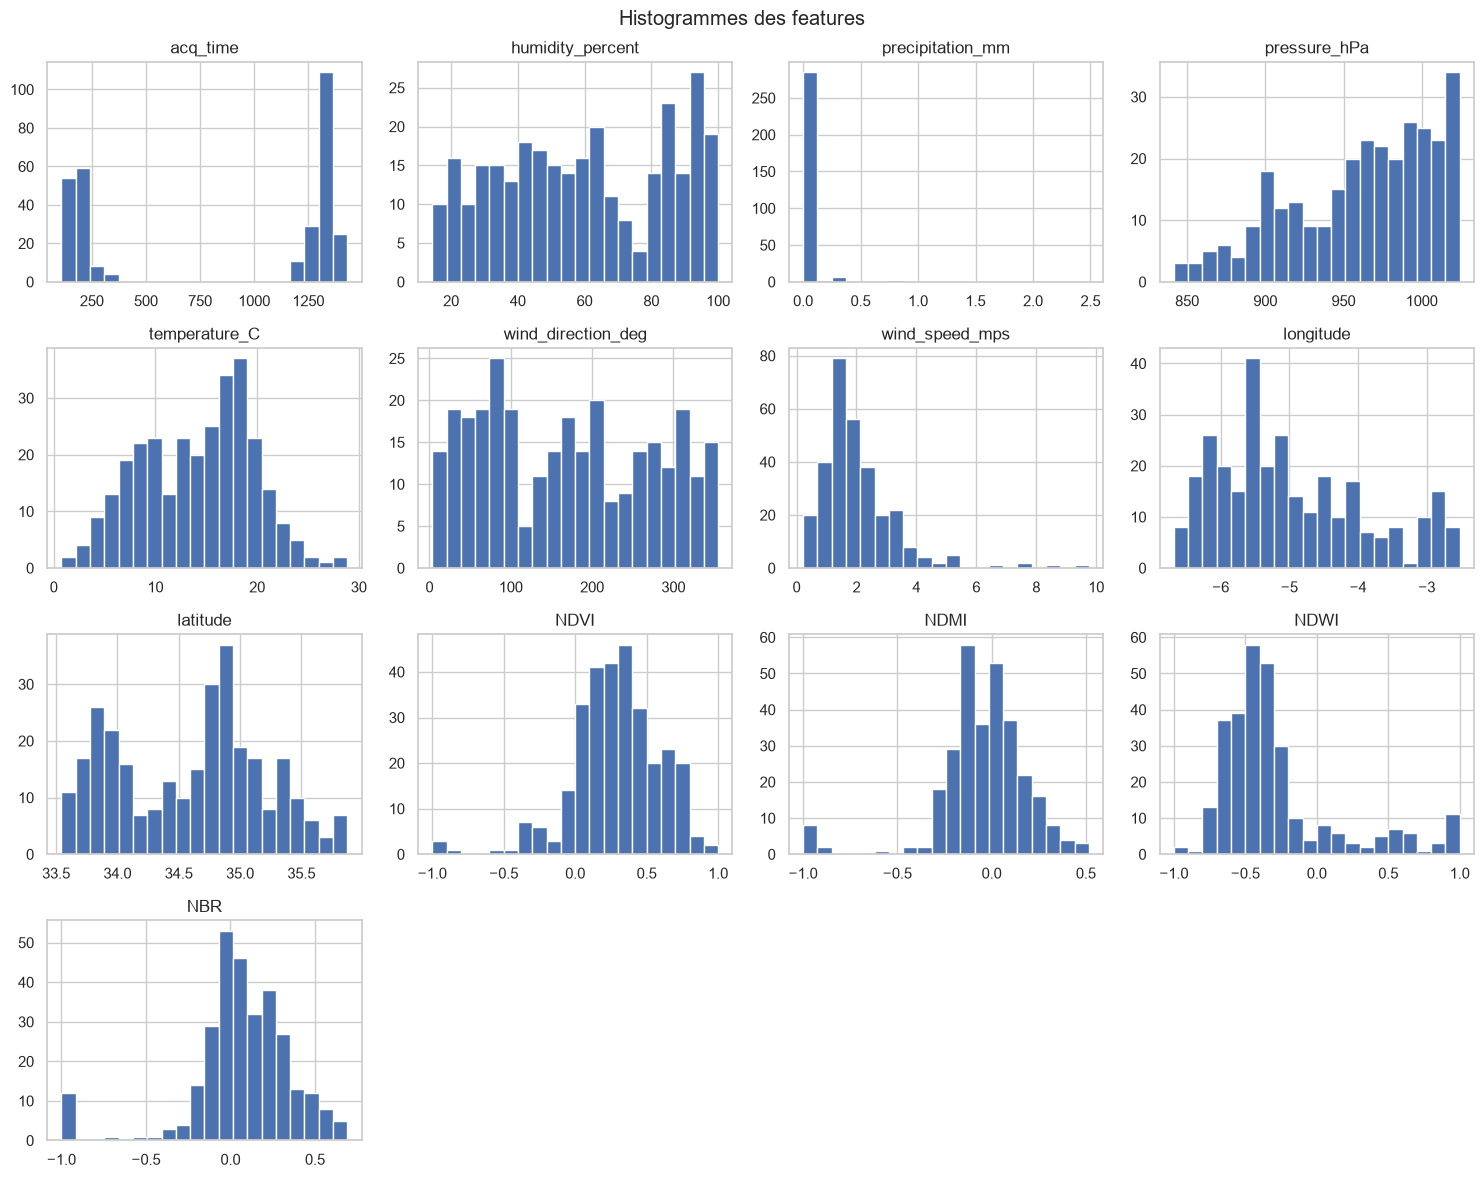

In [7]:
# Liste des variables numériques (sans la cible)
features = df.select_dtypes('number').columns.drop('Fire')

df[features].hist(bins=20, figsize=(15, 12))
plt.suptitle('Histogrammes des features')
plt.tight_layout()
plt.show()

## 4. Distribution des features par classe

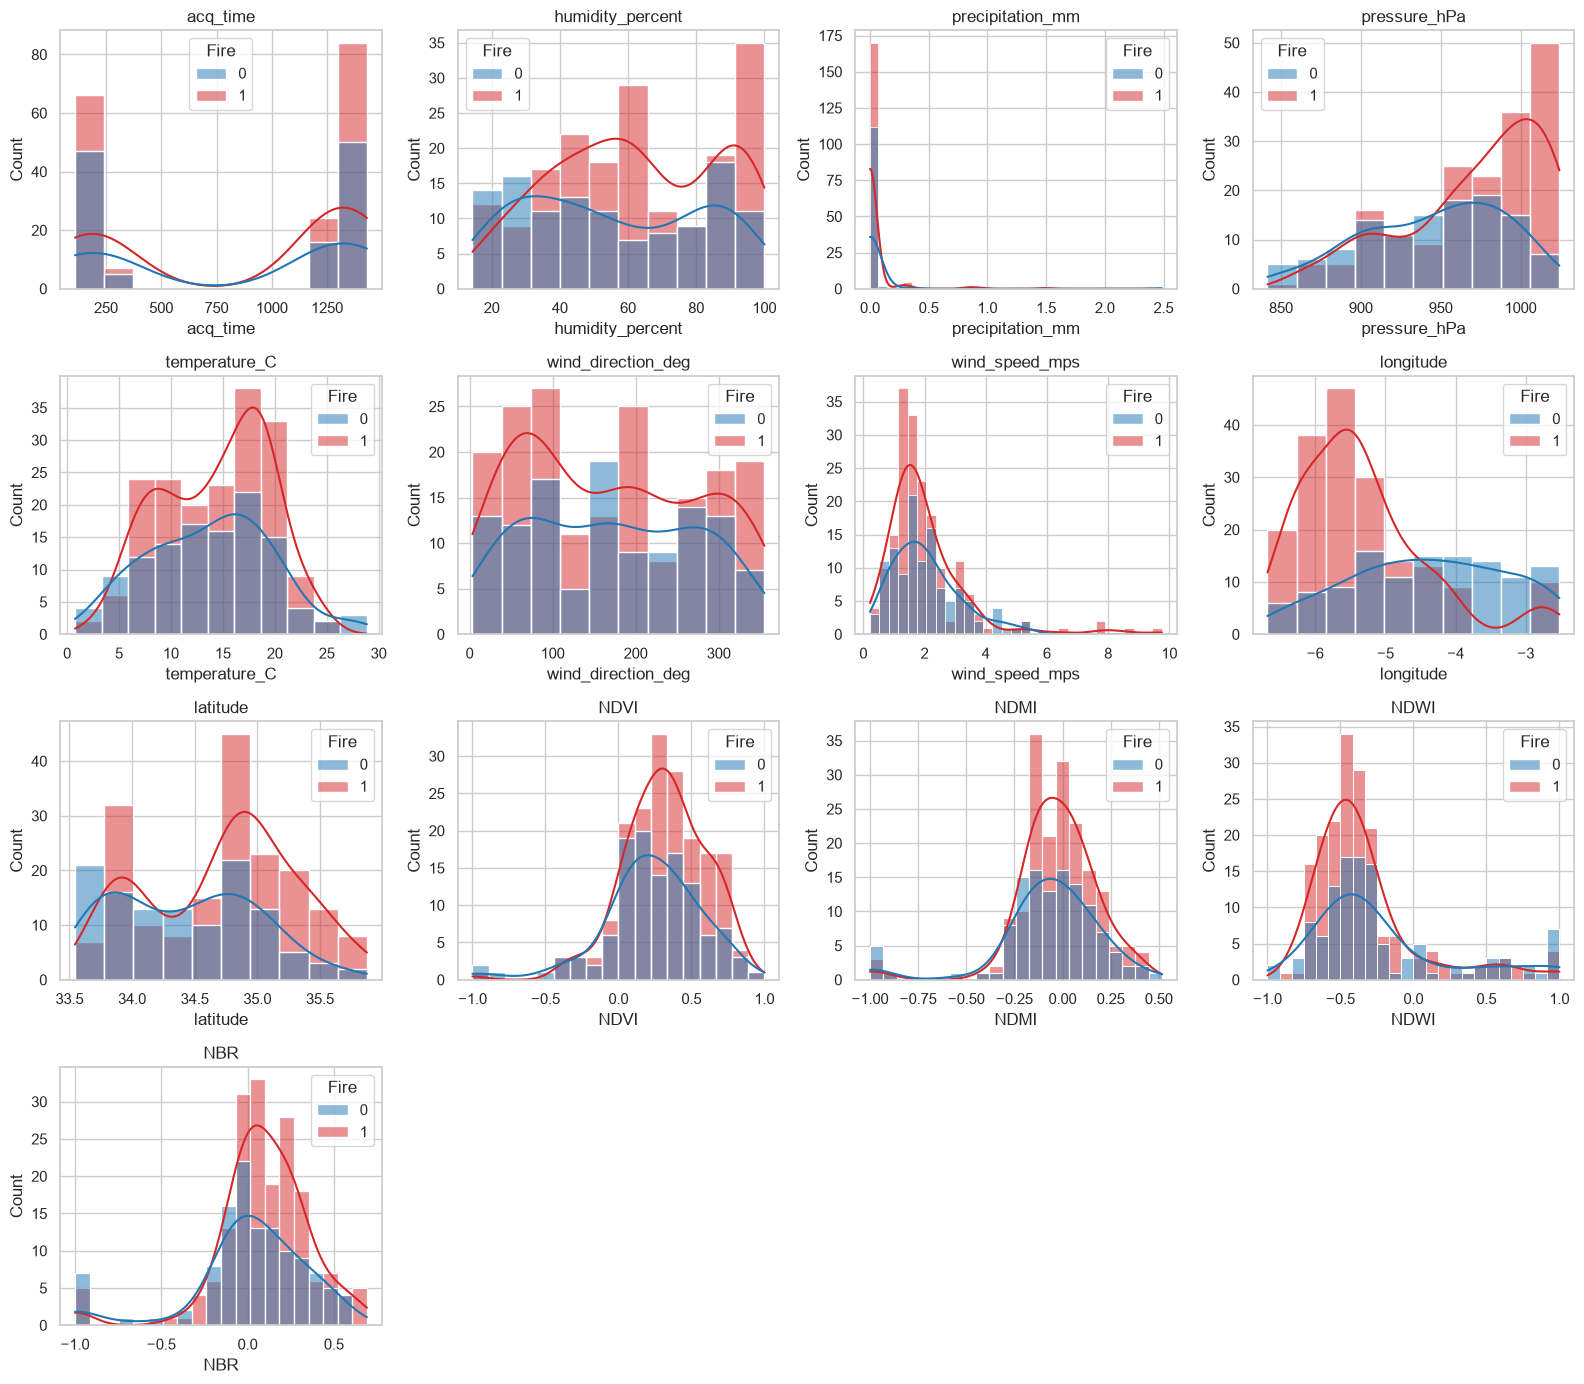

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for ax, col in zip(axes.flat, features):
    sns.histplot(data=df, x=col, hue='Fire', palette=couleurs, kde=True, ax=ax)
    ax.set_title(col)

# On cache les cases vides
for ax in axes.flat[len(features):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

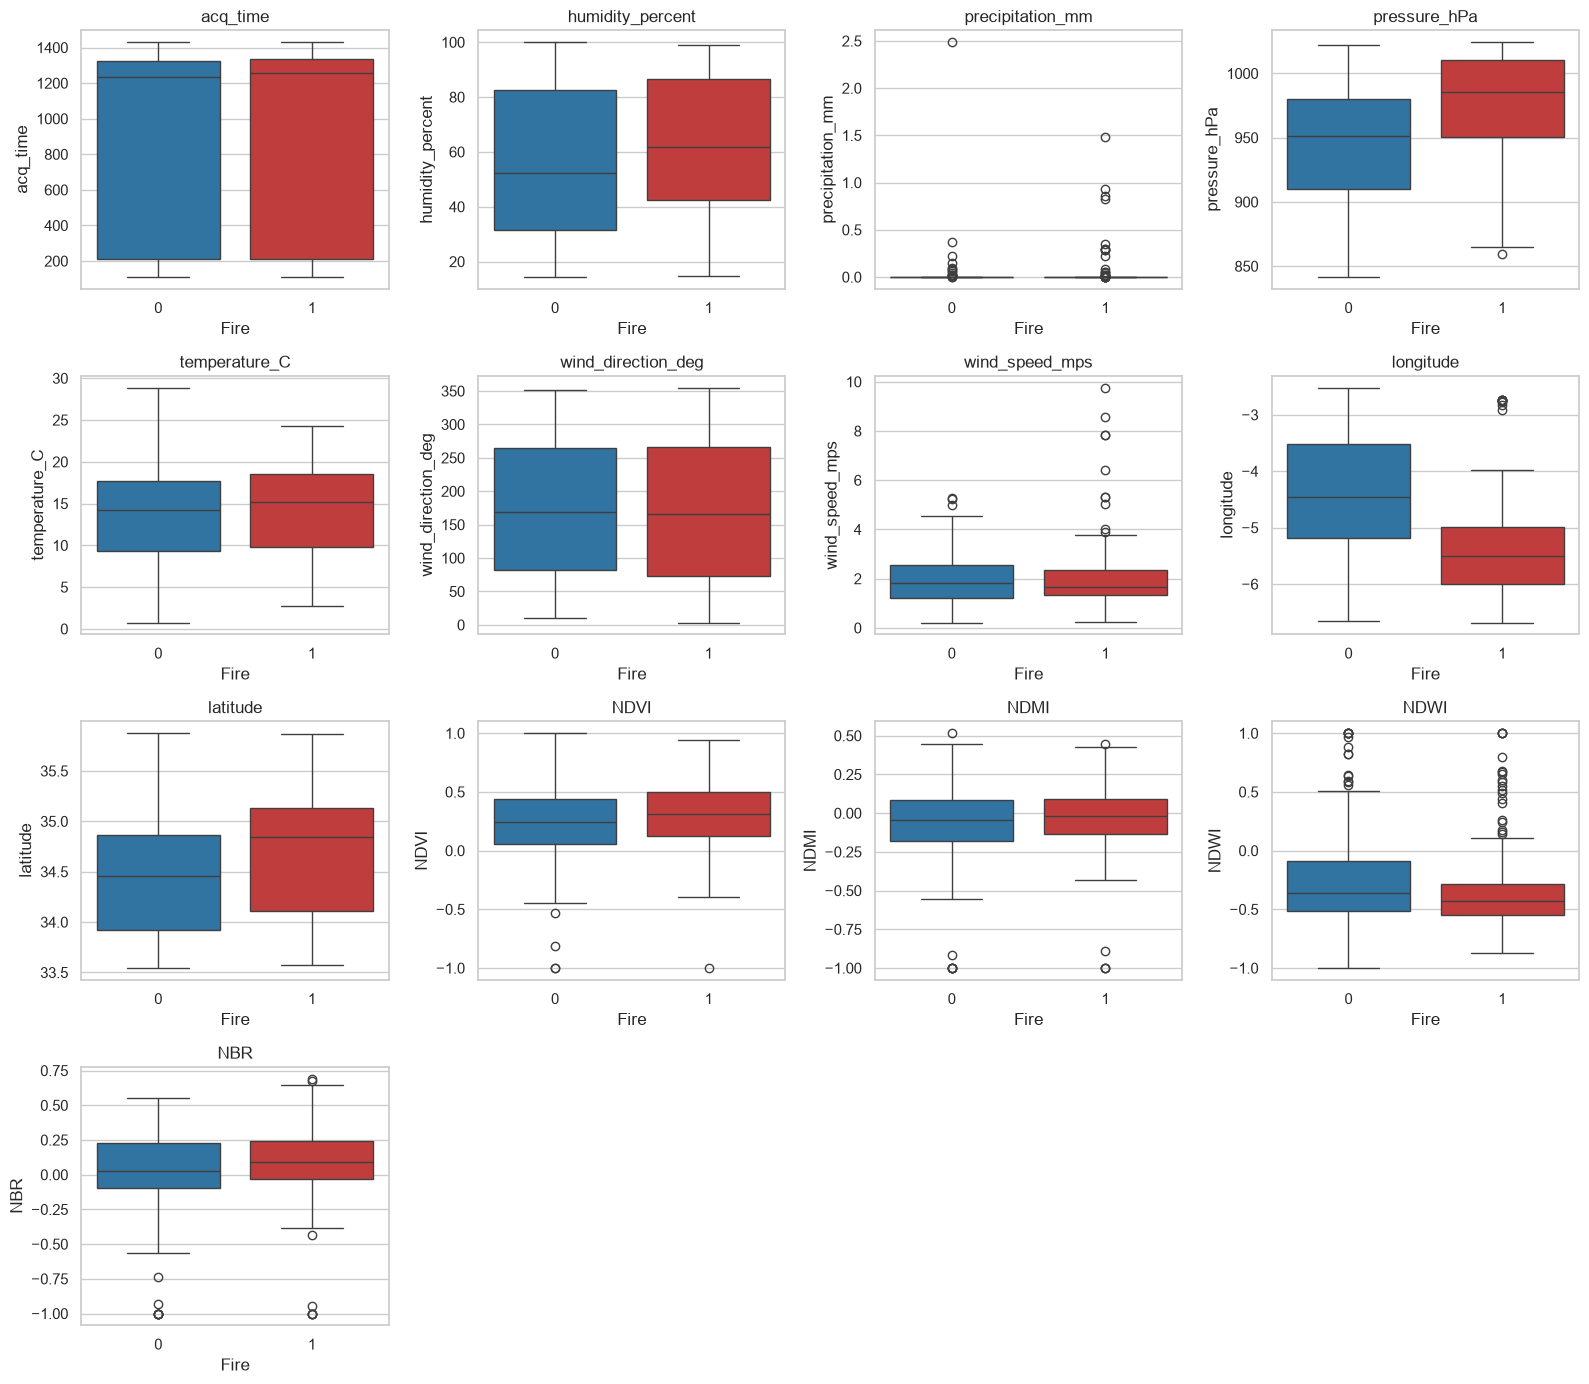

In [9]:
# Boxplots : comparer les valeurs de chaque feature entre les deux classes
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x='Fire', y=col, hue='Fire', palette=couleurs, legend=False, ax=ax)
    ax.set_title(col)

for ax in axes.flat[len(features):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [10]:
# Moyenne de chaque feature selon la classe
df.groupby('Fire')[features].mean().T.round(2)

Fire,0,1
acq_time,822.66,865.19
humidity_percent,55.62,62.37
precipitation_mm,0.03,0.03
pressure_hPa,945.60,972.29
temperature_C,13.74,14.31
wind_direction_deg,170.61,168.73
wind_speed_mps,2.03,2.02
longitude,-4.39,-5.35
latitude,34.42,34.72
NDVI,0.23,0.32


## 5. Répartition géographique des points (latitude / longitude)

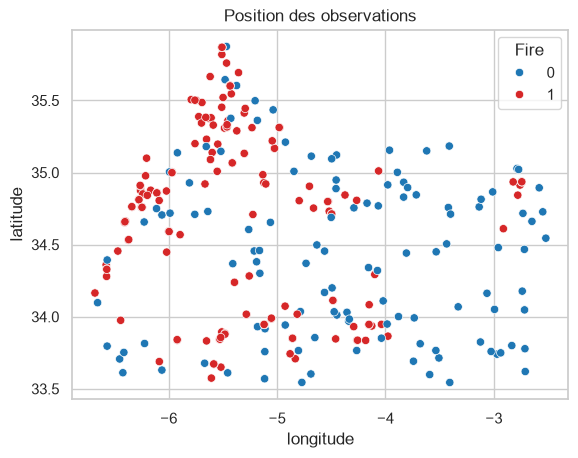

In [11]:
sns.scatterplot(data=df, x='longitude', y='latitude', hue='Fire', palette=couleurs)
plt.title('Position des observations')
plt.show()

In [12]:
# Carte interactive du Maroc
import folium

carte = folium.Map(location=[31.8, -7.0], zoom_start=5)

for _, ligne in df.iterrows():
    folium.CircleMarker(
        location=[ligne['latitude'], ligne['longitude']],
        radius=4,
        color='red' if ligne['Fire'] == 1 else 'blue',
        fill=True,
        popup=f"Fire = {ligne['Fire']} | date = {ligne['acq_date']}",
    ).add_to(carte)

carte

## 6. Matrice de corrélation

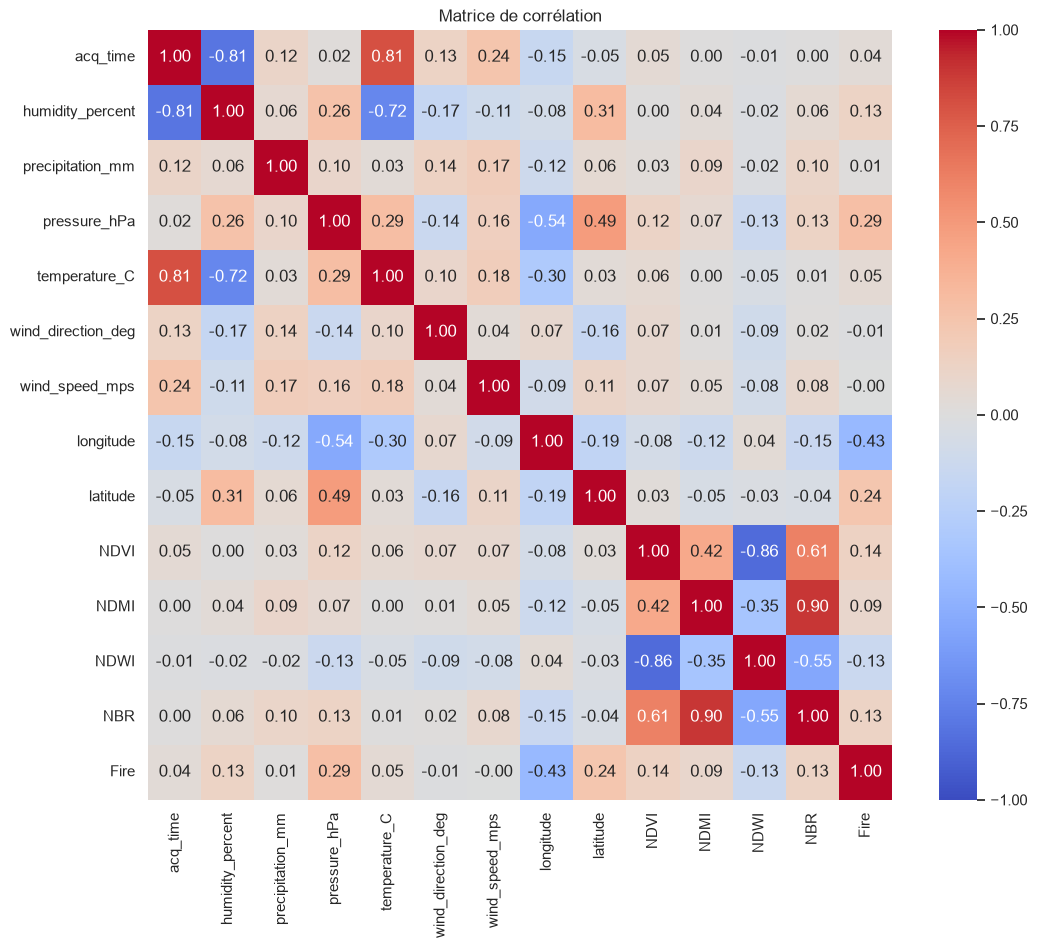

In [13]:
corr = df[features.tolist() + ['Fire']].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matrice de corrélation')
plt.show()

In [14]:
# Corrélation de chaque feature avec la cible, triée
corr['Fire'].drop('Fire').sort_values()

longitude            -0.430566
NDWI                 -0.134894
wind_direction_deg   -0.008849
wind_speed_mps       -0.004018
precipitation_mm      0.008110
acq_time              0.037069
temperature_C         0.050770
NDMI                  0.089532
NBR                   0.126455
humidity_percent      0.131273
NDVI                  0.139310
latitude              0.242160
pressure_hPa          0.285014
Name: Fire, dtype: float64

## Conclusion
- 299 observations, 15 colonnes, aucune valeur manquante ni doublon.
- Classes légèrement déséquilibrées (~60 % feu / 40 % pas de feu).
- `precipitation_mm` est nulle ou quasi nulle presque partout (seulement 14 valeurs > 0,1 mm) : distribution très asymétrique.
- Les variables de localisation (longitude, latitude, pression) sont les plus corrélées avec `Fire`.
- Certains indices sont très corrélés entre eux (NDVI / NDWI, NDMI / NBR) car calculés à partir des mêmes bandes satellite.